In [1]:
import matplotlib.pyplot as plt
import numpy as np
import segmentation_models as sm
import tensorflow as tf
import wandb

from networks import *

print(f'TensorFlow version: {tf.__version__}')
print(f'GPUs available: {tf.config.list_physical_devices("GPU")}')

Segmentation Models: using `keras` framework.
TensorFlow version: 2.12.0
GPUs available: []


In [ ]:
project_name = 'PVID-assignment-4'
wandb.login()

HEIGHT = 240
WIDTH = 320
CHANNELS = 3
IMAGE_SHAPE = (HEIGHT, WIDTH, CHANNELS)
BATCH_SIZE = 4

# Load data
dataset_path = 'input/'
_, _, test_ds = load_dataset(
    dataset_path, val_split=0.1, batch_size=BATCH_SIZE, height=HEIGHT, width=WIDTH,
    channels=CHANNELS, preprocess=None, augment=False, repeat=False,
)

In [13]:
custom_objects = {
    'jaccard_coef': jaccard_coef,
    'dice_coef': dice_coef,
    'iou_score': sm.metrics.IOUScore(),
    'f1-score': sm.metrics.FScore(),
}
metrics = [
    tf.keras.metrics.CategoricalAccuracy(),
    custom_objects['jaccard_coef'],
    custom_objects['dice_coef'],
    custom_objects['iou_score'],
    custom_objects['f1-score'],
]
loss = sm.losses.categorical_focal_dice_loss
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

## Load trained models

In [14]:
def load_model(run_id):
    api = wandb.Api()
    run = api.run(f'{project_name}/{run_id}')
    model_dir = run.file('model-best.h5').download(replace=True)

    model = tf.keras.models.load_model(model_dir.name, custom_objects=custom_objects, compile=False)
    model.compile(optimizer=optimizer, loss=loss, metrics=metrics)
    return model

In [15]:
unet = load_model('71o5hxt7')
wider_unet = load_model('mhiupvdb')
unet_plusplus = load_model('r8kgm8o1')
unet_3plus = load_model('zitcj310')
# suim_net = load_model('z3vm09qq')
# attention_unet = load_model('gv8pdtlt')
# attention_resunet = load_model('fa2gf3ru')

## Evaluation

In [16]:
unet_eval = unet.evaluate(test_ds)
wider_unet_eval = wider_unet.evaluate(test_ds)
unet_plusplus_eval = unet_plusplus.evaluate(test_ds)
unet_3plus_eval = unet_3plus.evaluate(test_ds)

28/28 [==============================] - 120s 4s/step - loss: 0.6253 - categorical_accuracy: 0.7834 - jaccard_coef: 0.5395 - dice_coef: 0.6964 - iou_score: 0.2980 - f1-score: 0.3862


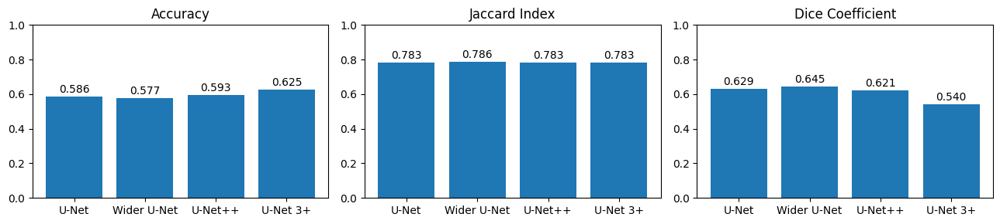

In [24]:
# Plot results
models = ['U-Net', 'Wider U-Net', 'U-Net++', 'U-Net 3+']
metric_names = ['Accuracy', 'Jaccard Index', 'Dice Coefficient']
evaluations = [
    unet_eval,
    wider_unet_eval,
    unet_plusplus_eval,
    unet_3plus_eval,
]

fig, axs = plt.subplots(1, 3, figsize=(13, 3))
for i, metric in enumerate(metric_names):
    ax = axs[i]
    ax.set_title(metric)
    ax.bar(models, [evaluation[i] for evaluation in evaluations])
    ax.set_ylim([0, 1])
    for j, v in enumerate([evaluation[i] for evaluation in evaluations]):
        ax.text(j, v + 0.01, f'{v:.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Visualize predictions

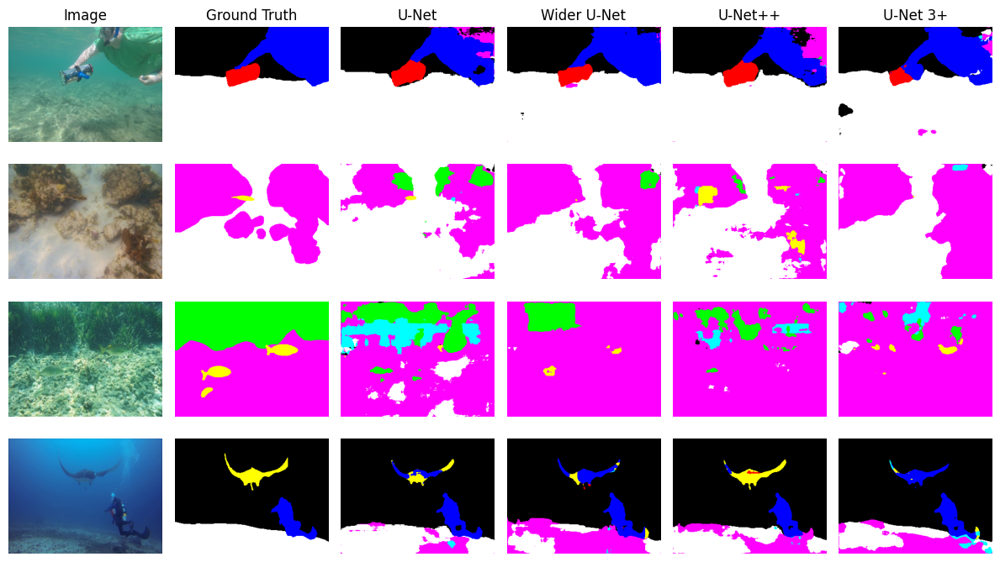

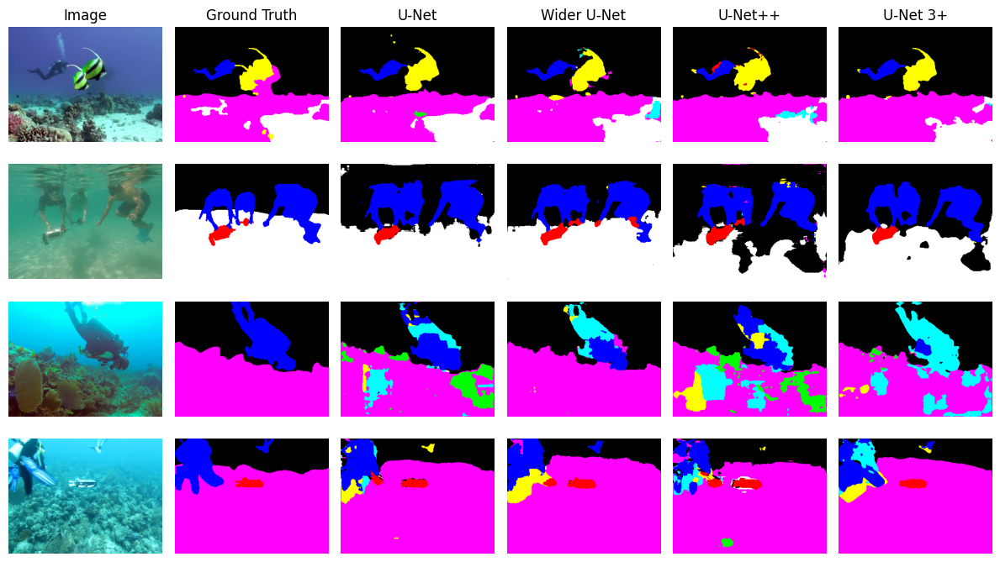

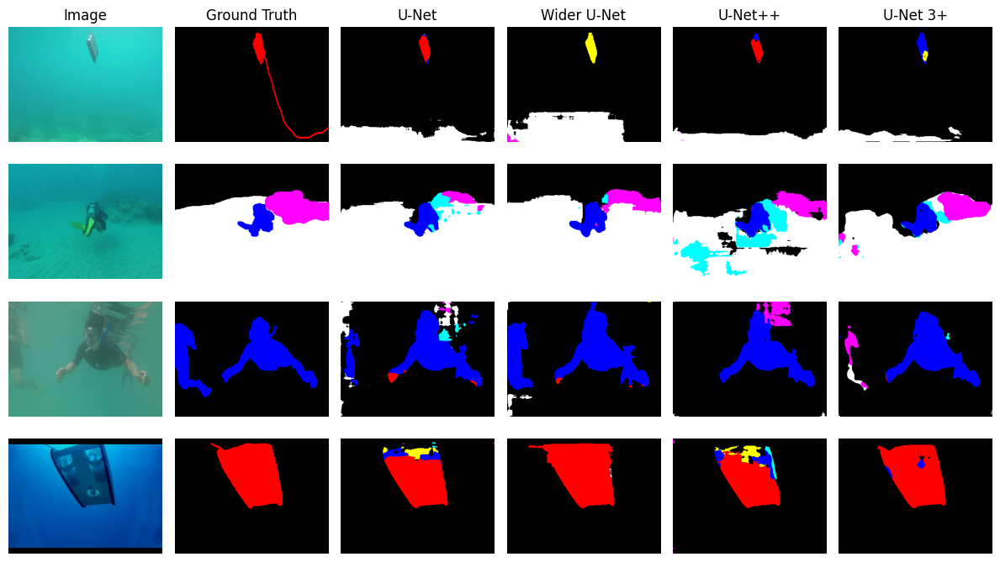

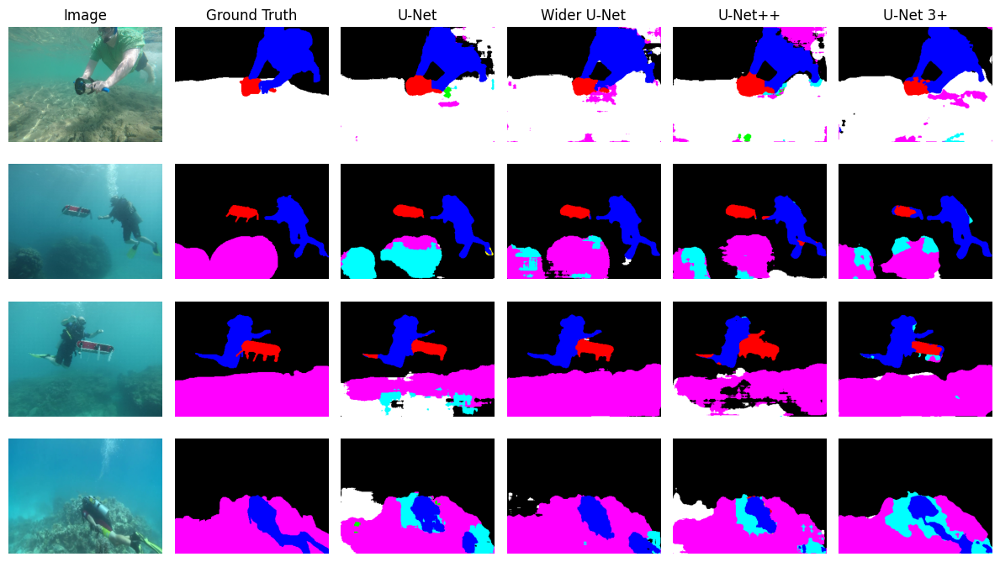

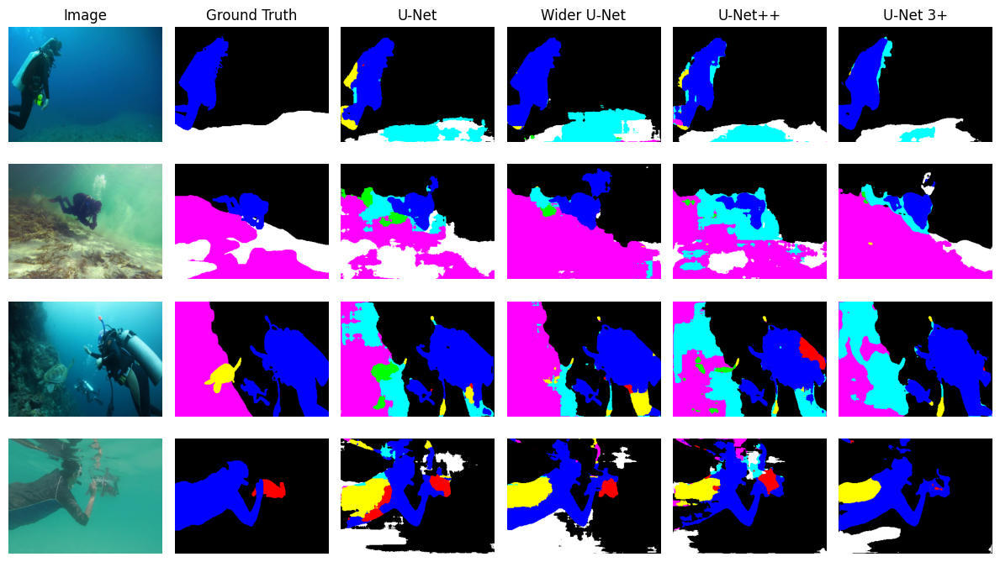

...

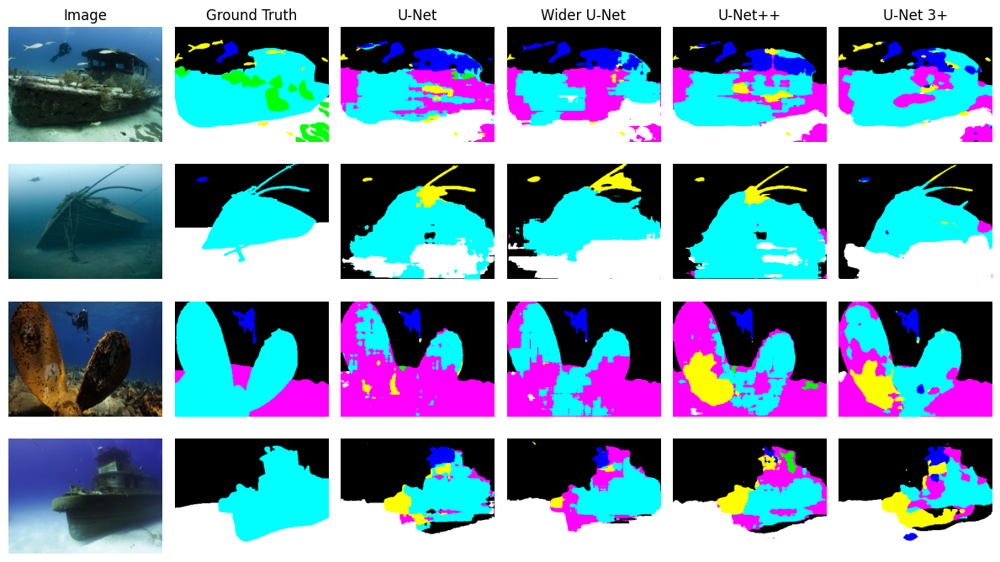

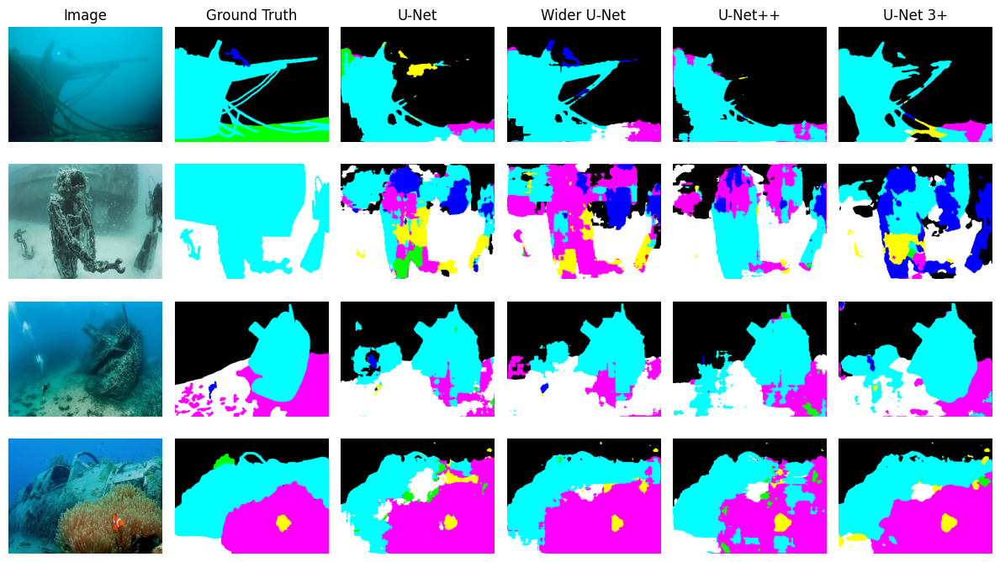

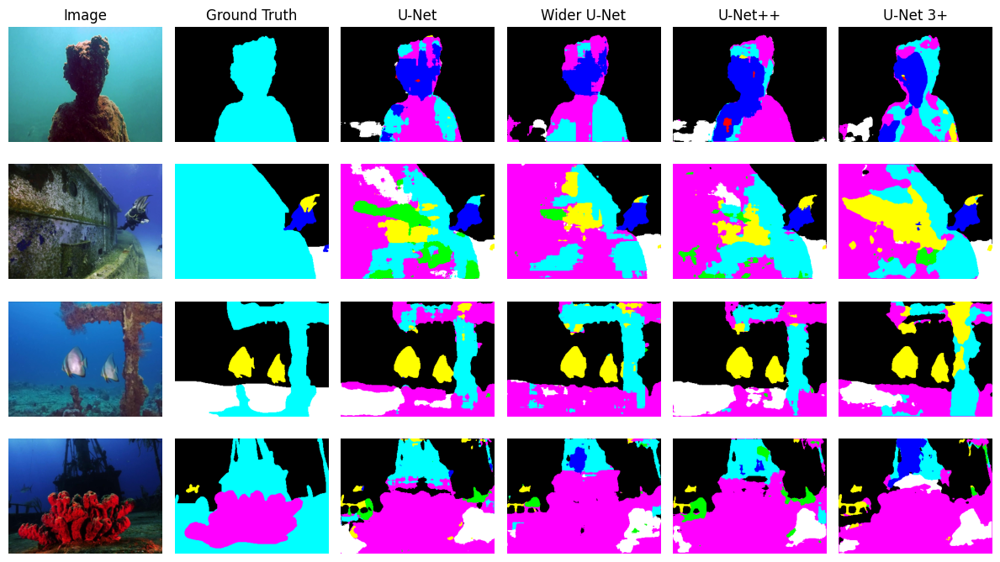

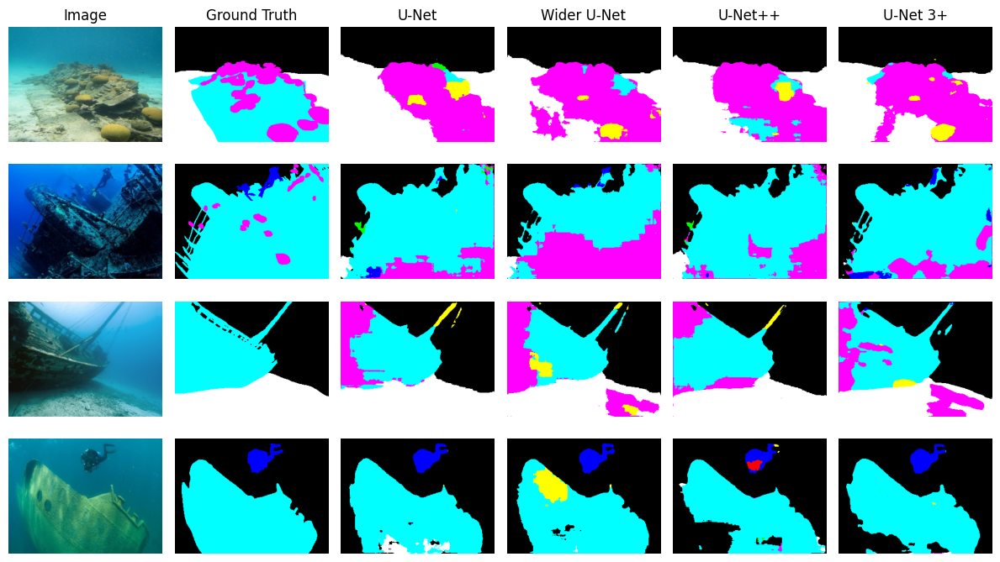

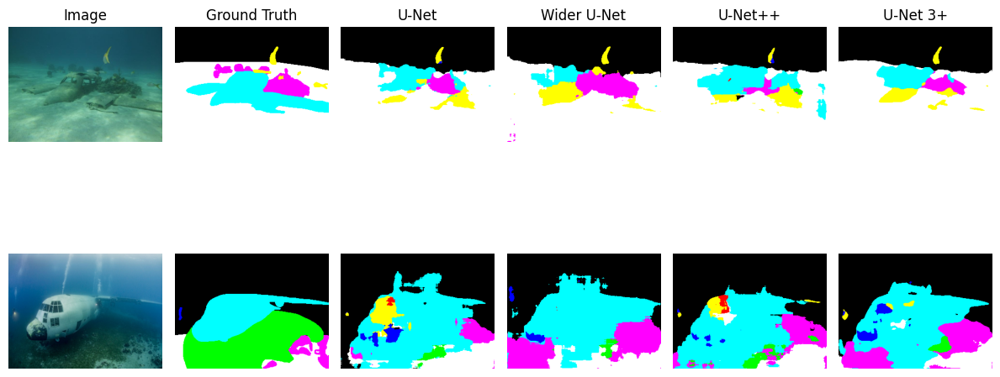

In [12]:
for index, (images, masks) in enumerate(test_ds):
    unet_pred = unet.predict(images, verbose=0)
    wider_unet_pred = wider_unet.predict(images, verbose=0)
    unet_plusplus_pred = unet_plusplus.predict(images, verbose=0)
    unet_3plus_pred = unet_3plus.predict(images, verbose=0)

    # Plot predictions
    n = len(images)
    fig, axs = plt.subplots(n, len(evaluations) + 2, figsize=(12, 7))

    for i in range(n):
        axs[i, 0].imshow(images[i])
        if i == 0:
            axs[i, 0].set_title('Image')
        axs[i, 0].axis('off')

        axs[i, 1].imshow(one_hot_to_rgb(masks[i]))
        if i == 0:
            axs[i, 1].set_title('Ground Truth')
        axs[i, 1].axis('off')

        axs[i, 2].imshow(one_hot_to_rgb(unet_pred[i]))
        if i == 0:
            axs[i, 2].set_title('U-Net')
        axs[i, 2].axis('off')

        axs[i, 3].imshow(one_hot_to_rgb(wider_unet_pred[i]))
        if i == 0:
            axs[i, 3].set_title('Wider U-Net')
        axs[i, 3].axis('off')

        axs[i, 4].imshow(one_hot_to_rgb(unet_plusplus_pred[i]))
        if i == 0:
            axs[i, 4].set_title('U-Net++')
        axs[i, 4].axis('off')

        axs[i, 5].imshow(one_hot_to_rgb(unet_3plus_pred[i]))
        if i == 0:
            axs[i, 5].set_title('U-Net 3+')
        axs[i, 5].axis('off')

    plt.tight_layout()
    plt.savefig(f'output/predictions-{index + 1:02d}.png')
    plt.show()